# Single Segments and the Comparison with Nested Sampling

We analyze simulated segments of LIGO Hanford and Livingston data on the GPU in the two set-ups of the paper. The first has three parameters, the chirp mass $\mathcal{M}_c$, the mass ratio $q$ and the effective spin $\chi_{\rm eff}$, with the distance integrated over a prior uniform in volume (Fig. 20). The second has two parameters, the source-frame primary mass $m_1^{\rm src}$ and the redshift $z$ of an equal-mass binary without spin, with the distance as a parameter (Fig. 21), as in the population analysis.

The sky position, orientation, polarization, phase and arrival time are never sampled because they are inside the tables, so a segment costs a fixed number of table reads at any SNR.

We draw the posteriors from the tables next to the `bilby` posteriors of the same segments, which are read from `../data/results` and were run with the settings of `../scripts/run_bilby.py`, and then follow the convergence with the truncation order (Figs. 16, 17 and 18). The tables (40 GB) are downloaded into `../tables/redshift` (see the README), and the analysis needs a GPU with at least 40 GB of memory.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import exmarg.search as search
import figures_validation as figures

## Three Parameters

The 16 segments hold one merger each at SNRs between 1.4 and 42. The series converges once $n_{\max} > {\rm SNR}^2/2$ (Sec. II), so with the tables at $n_{\max} = 120$ we analyze the segments up to SNR 15, and louder mergers are detected events of the catalog. The two segments of Fig. 20 are rows 6 and 9 at SNR 8.5 and 12.7.

The tables hold one table per signal power $s = u y^2$ with the distance $y = D_0/D_L$ as a parameter. In the three-parameter analysis each template reads every node it reaches and the distance is integrated over its prior in the code (`search.pe_intrinsic` with `prior='volume'`). We read the tables into memory once and keep them on the GPU.

In [2]:
segments = '../data/segments/three_parameters.npz'
data = np.load(segments)
print('segments:', data['d_H'].shape[0], '  frequency bins:', data['d_H'].shape[1], '  duration: %g s' % data['T'])
print('SNR:', np.round(data['snr'], 1))

start = time.time()
store = search.load_redshift_store('../tables/redshift', pinned=True)
print('tables read in %.0f s' % (time.time() - start))

segments: 16   frequency bins: 1969   duration: 4 s
SNR: [ 1.4  1.4  2.8  2.8  5.7  5.7  8.5  8.5 12.7 12.7 18.4 18.4 28.3 28.3
 42.4 42.4]


tables read in 23 s


The bank of Fig. 20 has 78,000 templates in $(M^{\rm det}, q, \chi_{\rm eff})$, with $M^{\rm det}$ the detector-frame total mass. We analyze it in ten pieces with two segments at a time so that the filter outputs fit on the GPU. The first call compiles the GPU kernels and copies the tables to the GPU, so we time the second.

In [3]:
bank = np.load('../data/banks/three_parameters.npy')
pieces = np.array_split(np.arange(len(bank)), 10)

start = time.time()
templates = [search.mass_bank(bank[piece], segments, 'gpu') for piece in pieces]
print('templates built in %.0f s (once)' % (time.time() - start))

rows = [6, 9]

def analyze(rows):
    ln_lambda = np.zeros((len(rows), len(bank)))
    for piece, piece_templates in zip(pieces, templates):
        result = search.pe_intrinsic(segments, piece_templates, store, rows=rows, chunk=2, prior='volume', resident=True)
        ln_lambda[:, piece] = result['ln_lambda']
    return ln_lambda

search.pe_intrinsic(segments, templates[0], store, rows=rows[:1], prior='volume', resident=True)   # compiles the kernels, copies the tables

start = time.time()
ln_lambda = analyze(rows)
seconds = time.time() - start
print('%d segments x %d templates in %.0f s: %.1f s per segment' % (len(rows), len(bank), seconds, seconds / len(rows)))

templates built in 44 s (once)


2 segments x 78000 templates in 66 s: 32.8 s per segment


The posterior is $\Lambda$ times the prior, here uniform over the bank with each template carrying the volume of its cell, and the Bayes factor against noise is the prior average of $\Lambda$. For the corner plot we draw samples from the cells and spread each sample uniformly inside its cell.

In [4]:
M, q, chi = bank[:, 0], bank[:, 1], bank[:, 2]

cell = np.ones(len(bank))
for axis in (M, q, chi):
    values = np.unique(axis)
    cell = cell * np.gradient(values)[np.searchsorted(values, axis)]
prior = cell / cell.sum()

def chirp_mass(M, q):
    return M * (q / (1 + q) ** 2) ** 0.6

paper = np.load('../data/results/ns_3p.npz')
ours = dict(paper)
rng = np.random.default_rng(1)
for e in range(2):
    lp = ln_lambda[e] + np.log(prior)
    ln_B = np.logaddexp.reduce(lp)
    weights = np.exp(lp - lp.max())
    pick = rng.choice(len(bank), size=400000, p=weights / weights.sum())
    samples = {}
    for name, axis in (('M', M), ('q', q), ('chi', chi)):
        values = np.unique(axis)
        width = np.gradient(values)[np.searchsorted(values, axis)]
        samples[name] = axis[pick] + (rng.random(pick.size) - 0.5) * width[pick]
    ours['e%d_ours_Mc' % e] = chirp_mass(samples['M'], samples['q'])
    ours['e%d_ours_q' % e] = samples['q']
    ours['e%d_ours_chi' % e] = samples['chi']
    ours['e%d_lnB_ours' % e] = ln_B
    print('segment %d: ln B = %.2f (this run), %.2f (paper), %.2f +- %.2f (bilby)'
          % (rows[e], ln_B, paper['e%d_lnB_ours' % e], paper['e%d_lnB_bilby' % e], paper['e%d_lnB_bilby_err' % e]))

segment 6: ln B = 13.25 (this run), 13.28 (paper), 13.23 +- 0.09 (bilby)


segment 9: ln B = 37.39 (this run), 37.43 (paper), 37.49 +- 0.10 (bilby)


Fig. 20 of the paper with the posterior from the tables in blue and the `bilby` samples in red. The likelihood ratio from the tables is integrated over the sky position and the orientation, so their panels show the `bilby` samples alone.

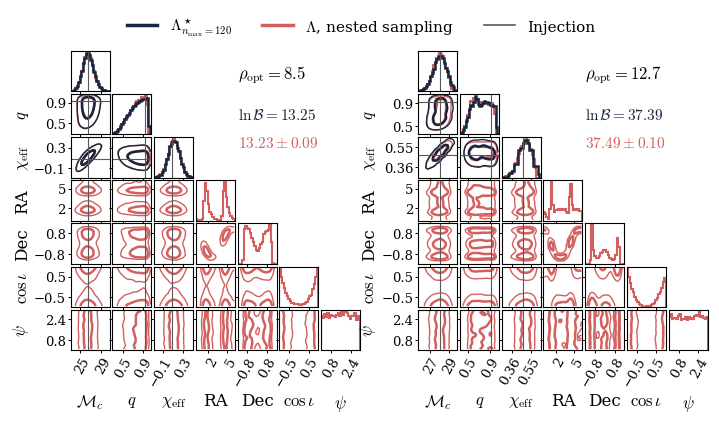

In [5]:
figures.fig_corner_3p(ours)

The other segments up to SNR 15 are analyzed two at a time, and the time per segment does not depend on the SNR.

In [6]:
others = [r for r in range(len(data['snr'])) if r not in rows and data['snr'][r] <= 15]
start = time.time()
analyze(others)
seconds = time.time() - start
print('%d segments in %.0f s: %.1f s per segment' % (len(others), seconds, seconds / len(others)))

8 segments in 240 s: 30.0 s per segment


## Two Parameters

There are 12 segments with one merger each at SNRs between 7 and 9, and the two segments of Fig. 21 are rows 9 and 7. The bank holds 3,517 detector-frame total masses, and with the distance as a parameter the analysis returns $\ln\Lambda$ for every mass on a grid of $1600 \times 1600$ points in $(m_1^{\rm src}, z)$. The tables are the same as above.

In [7]:
segments = '../data/segments/two_parameters.npz'
data = np.load(segments)
print('segments:', data['d_H'].shape[0], '  duration: %g s' % data['T'], '  SNR:', np.round(data['snr'], 1))

templates = search.mass_bank('../data/banks/two_parameters.npy', segments, 'gpu')
search.pe_redshift(segments, templates, store, rows=[0], resident=True)      # compiles the kernels

segments: 12   duration: 8 s   SNR: [7.3 7.6 7.4 8.8 7.7 8.4 7.9 9.  8.  8.9 8.2 8.2]


{'m1': array([  3.        ,   3.00734862,   3.01471523, ..., 149.26782971,
        149.63346703, 150.        ], shape=(1600,)),
 'z': array([0.02      , 0.02499062, 0.02998124, ..., 7.99001876, 7.99500938,
        8.        ], shape=(1600,)),
 'ln_lambda': array([[[       -inf,        -inf,        -inf, ..., -0.00388622,
          -0.00383066,        -inf],
         [       -inf,        -inf,        -inf, ..., -0.00333013,
          -0.00320666,        -inf],
         [       -inf,        -inf,        -inf, ..., -0.00301574,
          -0.00317288,        -inf],
         ...,
         [       -inf,        -inf,        -inf, ...,        -inf,
                 -inf,        -inf],
         [       -inf,        -inf,        -inf, ...,        -inf,
                 -inf,        -inf],
         [       -inf,        -inf,        -inf, ...,        -inf,
                 -inf,        -inf]]], shape=(1, 1600, 1600)),
 'ln_b': array([0.01559414]),
 'rows': array([0])}

In [8]:
n = data['d_H'].shape[0]
start = time.time()
result = search.pe_redshift(segments, templates, store, resident=True)
seconds = time.time() - start
print('%d segments in %.0f s: %.1f s per segment' % (n, seconds, seconds / n))

12 segments in 21 s: 1.8 s per segment


The prior is uniform in $M^{\rm det} = 2 m_1^{\rm src}(1+z)$ between 10 and 500 $M_\odot$ and proportional to $D^2$ in luminosity distance $D$, which gives $p(m_1^{\rm src}, z) \propto (1+z)\, D^2\, dD/dz$.

In [9]:
from astropy.cosmology import Planck18

m1, z = result['m1'], result['z']
DL = Planck18.luminosity_distance(z).value
prior = (1 + z) * DL ** 2 * np.gradient(DL, z)
M_det = 2 * m1[:, None] * (1 + z[None, :])
inside = (M_det >= 10) & (M_det <= 500)
cell = np.gradient(m1)[:, None] * np.gradient(z)[None, :]

paper = np.load('../data/results/ns_2p.npz')
ours = dict(paper)
for e, row in enumerate([9, 7]):
    lp = np.where(inside, result['ln_lambda'][row] + np.log(prior)[None, :], -np.inf)
    posterior = np.zeros_like(lp)
    finite = np.isfinite(lp)
    posterior[finite] = np.exp(lp[finite] - lp[finite].max())
    posterior = posterior * cell
    ours['e%d_ours_posterior' % e] = posterior / posterior.sum()
    print('segment %d: ln B = %.2f (this run), %.2f (paper), %.2f +- %.2f (bilby)'
          % (row, result['ln_b'][row], paper['e%d_lnB_ours' % e], paper['e%d_lnB_bilby' % e], paper['e%d_lnB_bilby_err' % e]))

segment 9: ln B = 9.72 (this run), 9.72 (paper), 9.70 +- 0.13 (bilby)
segment 7: ln B = 17.89 (this run), 17.89 (paper), 17.94 +- 0.13 (bilby)


Fig. 21 of the paper with the posterior from the tables in blue and the `bilby` samples in red.

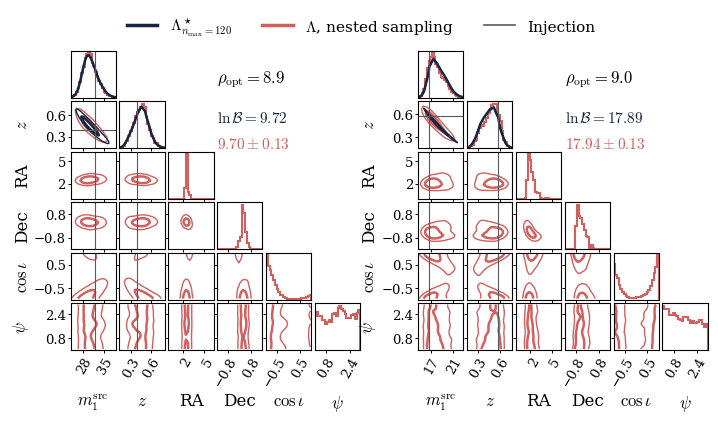

In [10]:
figures.fig_corner_2p(ours, np.load('../data/results/ns_2p_rho.npz'))

## The Cost of Nested Sampling

The run times of the `bilby` runs in `../data/results/bilby_runs.npz`, where the three-parameter runs take longer the louder the segment.

In [11]:
runs = np.load('../data/results/bilby_runs.npz')
for setup in ('three_parameters', 'two_parameters'):
    wall = runs[setup + '_wall_seconds']
    cores = runs[setup + '_cpu_cores']
    print('%-17s %d runs, %.0f to %.0f s on %s cores, median %.1f core hours'
          % (setup, wall.size, wall.min(), wall.max(), ' or '.join(str(c) for c in np.unique(cores)),
             np.median(wall * cores) / 3600))

three_parameters  15 runs, 47 to 28796 s on 32 cores, median 45.6 core hours
two_parameters    24 runs, 40 to 387 s on 28 or 128 cores, median 2.8 core hours


## Convergence with the Truncation Order (Figs. 16, 17 and 18)

We show $\ln\Lambda$ at the true parameters as a function of $n_{\max}$ (Fig. 16), the posterior of the same segment at three orders (Fig. 17) and the corrected likelihood ratio $\Lambda_\star$ of Eq. (B6) against nested sampling for 252 segments (Fig. 18).

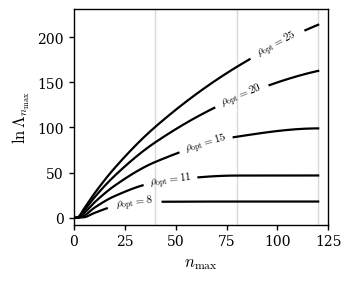

In [12]:
convergence = np.load('../data/results/convergence.npz')
figures.fig_lnlam_nmax(convergence)

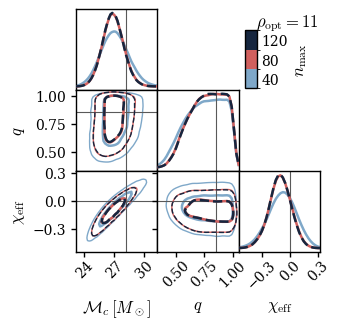

In [13]:
figures.fig_posterior_nmax(convergence)

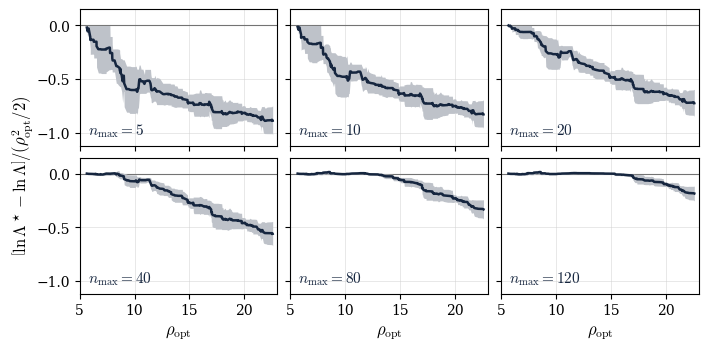

In [14]:
figures.fig_loud_ladder(np.load('../data/results/loud_ladder.npz'))